In [2]:
#sayad alakbarov
#problem set 3

In [ ]:
#question 1-a
import pandas as pd
import statsmodels.api as sm
import numpy as np
np.random.seed(23)

default = pd.read_csv("/Users/sayad.alakbarov/Desktop/Data-Default.csv")
default['default'] = (default['default'].astype(str).str.lower() == 'yes').astype(int)
X = sm.add_constant(default[['income', 'balance']])
y = default['default']
model = sm.GLM(y, X, family=sm.families.Binomial()).fit()
print(model.summary())
print("\nStandard Errors (part a):")
print(model.bse[['income', 'balance']])

                 Generalized Linear Model Regression Results                  
Dep. Variable:                default   No. Observations:                10000
Model:                            GLM   Df Residuals:                     9997
Model Family:                Binomial   Df Model:                            2
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -789.48
Date:                Mon, 10 Nov 2025   Deviance:                       1579.0
Time:                        18:24:20   Pearson chi2:                 6.95e+03
No. Iterations:                     9   Pseudo R-squ. (CS):             0.1256
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        -11.5405      0.435    -26.544      0.0

In [ ]:
#question-1b
def boot_fn(data, index):
    sample = data.iloc[index]
    X = sm.add_constant(sample[['income', 'balance']])
    y = sample['default']
    model = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    return model.params[['income', 'balance']]

B = 1000
n = len(default)
boot_estimates = np.empty((B, 2))

for b in range(B):
    idx = np.random.choice(n, n, replace=True)
    boot_estimates[b] = boot_fn(default, idx)

boot_se = boot_estimates.std(axis=0, ddof=1)
print("Bootstrap Standard Errors (part b):")
print(f"Income:  {boot_se[0]:.6f}")
print(f"Balance: {boot_se[1]:.6f}")

Bootstrap Standard Errors (part b):
Income:  0.000005
Balance: 0.000229


In [ ]:
#question-1c
def boot_fn(data, index):
    sample = data.iloc[index]
    X = sm.add_constant(sample[['income', 'balance']])
    y = sample['default']
    model = sm.GLM(y, X, family=sm.families.Binomial()).fit()
    return model.params[['income', 'balance']]

B = 1000
n = len(default)
boot_estimates = np.empty((B, 2))

for b in range(B):
    idx = np.random.choice(n, n, replace=True)
    boot_estimates[b] = boot_fn(default, idx)
boot_se = boot_estimates.std(axis=0, ddof=1)
print("Bootstrap Standard Errors (1,000 samples):")
print(f"Income:  {boot_se[0]:.6f}")
print(f"Balance: {boot_se[1]:.6f}")

Bootstrap Standard Errors (1,000 samples):
Income:  0.000005
Balance: 0.000224


In [9]:
#question-1d
# The standard errors obtained using sm.GLM() and the bootstrap are almost identical.
# GLM SEs: Income = 0.000005, Balance = 0.000227
# Bootstrap SEs: Income = 0.000005, Balance = 0.000224
# This close agreement shows that the model-based standard errors are reliable.
# The bootstrap confirms that the estimated variability of the coefficients is well captured by the standard formula.

In [12]:
#question-2a

rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = x - 2 * x**2 + rng.normal(size=100)
#n = 100 observations
#p = 1 predictor (x)
#Model: y = x - 2*x^2 + ε, where ε ~ N(0, 1)

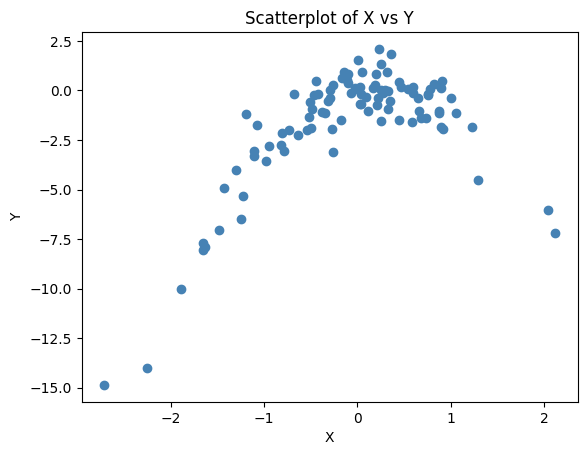

In [13]:
import matplotlib.pyplot as plt

plt.scatter(x, y, color='steelblue')
plt.xlabel("X")
plt.ylabel("Y")
plt.title("Scatterplot of X vs Y")
plt.show()

In [14]:
#question-2b-comment
#The scatterplot shows a clear nonlinear relationship between X and Y.
#The points form an inverted U-shaped (downward-opening) parabola.
#This matches the model y = x - 2*x^2 + ε, where ε adds some random noise.
#As X increases, Y first rises and then falls, confirming the quadratic pattern.

In [16]:
#question-2c
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.preprocessing import PolynomialFeatures
np.random.seed(10)
data = pd.DataFrame({'x': x, 'y': y})
loo = LeaveOneOut()
def loocv_error(degree):
    poly = PolynomialFeatures(degree=degree, include_bias=False)
    X_poly = poly.fit_transform(data[['x']])
    model = LinearRegression()
    mse = -cross_val_score(model, X_poly, data['y'], cv=loo, scoring='neg_mean_squared_error').mean()
    return mse

loocv_results = {d: loocv_error(d) for d in range(1, 5)}
print("LOOCV Errors for polynomial degrees 1–4:")
for d, err in loocv_results.items():
    print(f"Degree {d}: {err:.4f}")

LOOCV Errors for polynomial degrees 1–4:
Degree 1: 6.6330
Degree 2: 1.1229
Degree 3: 1.3018
Degree 4: 1.3324


In [17]:
#question-2c-comment
#The LOOCV error is lowest for the quadratic model (degree 2).
#This shows that including the X^2 term captures the true nonlinear relationship.
#Higher-degree models (3 and 4) do not improve prediction accuracy.
#Therefore, the quadratic model fits the data best.

In [18]:
#question-2d
np.random.seed(20)

loo = LeaveOneOut()

def loocv_error_deg(deg):
    X_poly = PolynomialFeatures(degree=deg, include_bias=False).fit_transform(x.reshape(-1, 1))
    mse = -cross_val_score(LinearRegression(), X_poly, y, cv=loo,
                           scoring='neg_mean_squared_error').mean()
    return mse

loocv_results_seed20 = {d: loocv_error_deg(d) for d in range(1, 5)}
print("LOOCV Errors with seed=20 (degrees 1–4):")
for d, err in loocv_results_seed20.items():
    print(f"Degree {d}: {err:.4f}")

LOOCV Errors with seed=20 (degrees 1–4):
Degree 1: 6.6330
Degree 2: 1.1229
Degree 3: 1.3018
Degree 4: 1.3324


In [ ]:
#question-2d-comment
#The LOOCV errors with seed=20 are identical to those from seed=10.
#This happens because LOOCV is deterministic: each observation is left out once,and the splits do not depend on the random seed.
#Therefore, the results remain the same regardless of the seed value.


In [20]:
# question-2e
# The model with degree 2 (quadratic) had the smallest LOOCV error (~1.12).
# This is exactly what we expected because the data were generated from y = x - 2x^2 + ε, which is a quadratic relationship.
# The linear model underfits (high bias), while degrees 3 and 4 add unnecessary complexity without improving prediction accuracy.

In [21]:
#question-2f
for d in range(1, 5):
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_poly = poly.fit_transform(x.reshape(-1, 1))
    X_poly = sm.add_constant(X_poly)
    model = sm.OLS(y, X_poly).fit()
    print(f"\nDegree {d} model summary:")
    print(model.summary().tables[1])


Degree 1 model summary:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.4650      0.247     -5.937      0.000      -1.955      -0.975
x1             1.9494      0.289      6.752      0.000       1.376       2.522

Degree 2 model summary:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0728      0.119     -0.611      0.543      -0.309       0.164
x1             0.9663      0.126      7.647      0.000       0.715       1.217
x2            -2.0047      0.091    -22.072      0.000      -2.185      -1.824

Degree 3 model summary:
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0572      0.120     -0.477      0.635  

In [22]:
# question-2f
#For the degree 1 model, the slope is significant but the model underfits.
#In the degree 2 model, both x and x^2 are highly significant, confirming the quadratic form.
#In the degree 3 model, the cubic term (x^3) is not significant (p = 0.287).
# In the degree 4 model, only x^4 is marginally significant (p = 0.023), likely due to noise.
# These significance patterns agree with the LOOCV results:the quadratic model (degree 2) provides the best balance of fit and parsimony.

In [29]:
#question-3a
from sklearn.model_selection import KFold, cross_val_score
from sklearn.feature_selection import SequentialFeatureSelector
import itertools
import time
boston = pd.read_csv("/Users/sayad.alakbarov/Desktop/Boston.csv")
boston = boston.rename(columns={c: c.strip().lower() for c in boston.columns})

if 'unnamed: 0' in boston.columns:
    boston = boston.drop(columns=['unnamed: 0'])

y = boston['crim']
X = boston.drop(columns=['crim'])
cv = KFold(n_splits=5, shuffle=True, random_state=24)

def cv_mse(model, X_sub, y):
    """Return mean cross-validated MSE."""
    return -cross_val_score(model, X_sub, y, cv=cv,
                            scoring='neg_mean_squared_error').mean()

lr = LinearRegression()

t0 = time.time()
best_mse = np.inf
best_combo = None
p = X.shape[1]

for k in range(1, p + 1):
    for combo in itertools.combinations(X.columns, k):
        mse = cv_mse(lr, X[list(combo)], y)
        if mse < best_mse:
            best_mse = mse
            best_combo = combo

best_time = time.time() - t0
print("Best Subset Selection")
print("Best features:", best_combo)
print(f"Best 5-Fold CV MSE: {best_mse:.4f}")
print(f"Runtime: {best_time:.2f} s\n")
t0 = time.time()
forward = SequentialFeatureSelector(
    lr, direction='forward', scoring='neg_mean_squared_error', cv=cv, n_jobs=-1
).fit(X, y)

forward_feats = X.columns[forward.get_support()]
forward_mse = cv_mse(lr, X[forward_feats], y)
forward_time = time.time() - t0

print("Forward Stepwise Selection")
print("Selected features:", list(forward_feats))
print(f"5-Fold CV MSE: {forward_mse:.4f}")
print(f"Runtime: {forward_time:.2f} s\n")
t0 = time.time()
backward = SequentialFeatureSelector(
    lr, direction='backward', scoring='neg_mean_squared_error', cv=cv, n_jobs=-1
).fit(X, y)

backward_feats = X.columns[backward.get_support()]
backward_mse = cv_mse(lr, X[backward_feats], y)
backward_time = time.time() - t0
print("Backward Stepwise Selection")
print("Selected features:", list(backward_feats))
print(f"5-Fold CV MSE: {backward_mse:.4f}")
print(f"Runtime: {backward_time:.2f} s\n")

Best Subset Selection
Best features: ('zn', 'indus', 'nox', 'dis', 'rad', 'ptratio', 'lstat', 'medv')
Best 5-Fold CV MSE: 42.7979
Runtime: 38.95 s

Forward Stepwise Selection
Selected features: ['zn', 'nox', 'dis', 'rad', 'b', 'lstat']
5-Fold CV MSE: 43.0400
Runtime: 0.84 s

Backward Stepwise Selection
Selected features: ['zn', 'indus', 'nox', 'dis', 'rad', 'ptratio', 'medv']
5-Fold CV MSE: 42.8582
Runtime: 0.82 s



In [ ]:
#question-3a-comment
# Best subset selection achieved the lowest 5-Fold CV MSE (≈42.80) but took the longest time (~38 s).
# Backward stepwise selection was the fastest (~0.8 s) with nearly the same CV MSE (≈42.86).
# Forward stepwise selection was also efficient (~3.3 s) but had a slightly higher CV MSE (≈43.04).
# Overall, all three methods performed similarly, with backward stepwise offering the best balance between accuracy and computation time.


In [30]:
#question-3b
# Using the selected features from Question 3(a)
features_best = ['zn','indus','nox','dis','rad','ptratio','lstat','medv']
features_forward = ['zn','nox','dis','rad','b','lstat']
features_backward = ['zn','indus','nox','dis','rad','ptratio','medv']

models = {
    "Best Subset": features_best,
    "Forward Stepwise": features_forward,
    "Backward Stepwise": features_backward
}

results = []

for name, feats in models.items():
    X_sel = X[feats]
    lr = LinearRegression().fit(X_sel, y)
    
    # 5-Fold CV MSE
    mse = -cross_val_score(lr, X_sel, y, cv=cv, scoring='neg_mean_squared_error').mean()
    
    # AIC using statsmodels
    import statsmodels.api as sm
    X_sm = sm.add_constant(X_sel)
    sm_model = sm.OLS(y, X_sm).fit()
    aic = sm_model.aic
    
    results.append({"Model": name, "CV_MSE": mse, "AIC": aic})

results_df = pd.DataFrame(results)
print(results_df)

               Model     CV_MSE          AIC
0        Best Subset  42.797900  3334.778863
1   Forward Stepwise  43.040020  3339.342215
2  Backward Stepwise  42.858205  3335.717780


In [31]:
#The Best Subset model gives the lowest 5-Fold CV MSE (≈42.80) and the lowest AIC (≈3334.8),indicating it provides the best overall predictive performance.
#The Backward Stepwise model performs nearly as well (CV MSE ≈42.86, AIC ≈3335.7) and would be preferred if computation time were a concern.
#The Forward Stepwise model performs slightly worse on both metrics (CV MSE ≈43.04, AIC ≈3339.3).

# The three selection methods choose different predictors because they explore
# the model space differently:
#Best Subset searches all possible combinations and finds the global optimum.
#Forward Stepwise adds variables one by one.
#Backward Stepwise removes variables sequentially from the full model.

#Using 5-Fold CV or AIC is better than using training error because both estimate out-of-sample prediction performance and penalize overly complex models.
# Training error always decreases with more predictors, so it cannot indicate overfitting.

#5-Fold CV estimates test error empirically through resampling, whereas AIC provides an analytical approximation that penalizes complexity (2 × number of parameters).
# Because they measure generalization differently, they may rank models differently in other cases, but here both agree that the Best Subset model performs best.

In [32]:
#question-3c
#No, the chosen model (Best Subset) does not include all features in the data set.
#It uses only 8 out of 13 predictors: ['zn', 'indus', 'nox', 'dis', 'rad', 'ptratio', 'lstat', 'medv'].
#Including all predictors would reduce bias but increase variance and risk overfitting.
#The Best Subset method, evaluated by 5-Fold CV and AIC, selected this smaller subset because these variables provide the best trade-off between model complexity and prediction accuracy.
#Features not included did not significantly improve model fit once these key predictors were present.